<a href="https://colab.research.google.com/github/dimplehasinipalla/machine-learning-sem5/blob/main/Random_Forests.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
import seaborn as sn
import matplotlib.pyplot as plt
from sklearn import tree

# Creating a simulated dataset representing the "Fruit Basket"
# Class 0: Apple (Class-A, majority) | Class 1: Banana (Class-B, minority)
np.random.seed(42)
n_samples = 300

# Apples (Class-A) make up 70% of the basket
apples_f1 = np.random.normal(2.0, 0.5, int(n_samples * 0.7))
apples_f2 = np.random.normal(3.0, 0.5, int(n_samples * 0.7))
apples_target = np.zeros(int(n_samples * 0.7))

# Bananas (Class-B) make up 30% of the basket
bananas_f1 = np.random.normal(5.0, 0.5, int(n_samples * 0.3))
bananas_f2 = np.random.normal(1.0, 0.5, int(n_samples * 0.3))
bananas_target = np.ones(int(n_samples * 0.3))

f1 = np.concatenate([apples_f1, bananas_f1])
f2 = np.concatenate([apples_f2, bananas_f2])
target = np.concatenate([apples_target, bananas_target])

data = pd.DataFrame({
    'Feature_Shape': f1,
    'Feature_Sweetness': f2,
    'Fruit_Class': target
})

print("Dataset Shape:", data.shape)
display(data.head())

Dataset Shape: (300, 3)


,Feature_Shape,Feature_Sweetness,Fruit_Class
0,2.248357,3.285445,0.0
1,1.930868,3.567783,0.0
2,2.323844,3.477001,0.0
3,2.761515,3.325696,0.0
4,1.882923,2.842365,0.0


In [ ]:
# Assigning dependent and independent variables
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

# Splitting the dataset into Training and Testing Dataset (70-30 split)
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Preprocessing Data with StandardScaler
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (210, 2)
Testing data shape: (90, 2)


Random Forest Classifier

Confusion Matrix:
 [[64  0]
 [ 0 26]]
Accuracy Score: 1.0
Accuracy in Percentage: 100 %

Classification Report:
               precision    recall  f1-score   support

         0.0       1.00      1.00      1.00        64
         1.0       1.00      1.00      1.00        26

    accuracy                           1.00        90
   macro avg       1.00      1.00      1.00        90
weighted avg       1.00      1.00      1.00        90



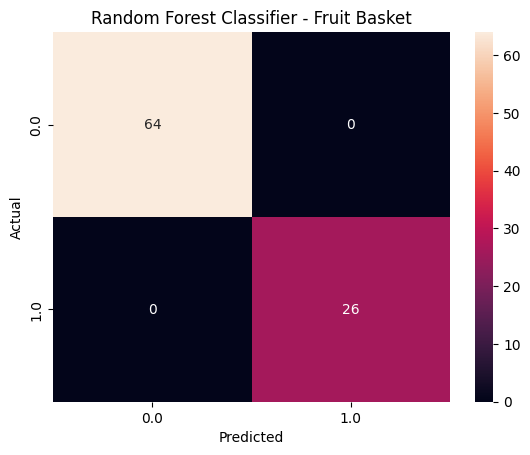


--- Final Conclusion for Exercise 12.6 Q1 ---
The fruit likely to be taken most often via Majority-Voting is: Apple (Class-A)


In [ ]:
# Fitting the Random Forest Classifier Model
model = RandomForestClassifier(n_estimators=10, criterion='entropy', random_state=0)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

# Evaluation Metrics
print('Random Forest Classifier')
conf_mat = metrics.confusion_matrix(y_test, y_pred)
print('\nConfusion Matrix:\n', conf_mat)

accuracy_score_val = accuracy_score(y_test, y_pred)
print('Accuracy Score:', accuracy_score_val)
print('Accuracy in Percentage:', int(accuracy_score_val * 100), '%')
print('\nClassification Report:\n', classification_report(y_pred, y_test))

# Visualizing Confusion Matrix
conf_df = pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'])
sn.heatmap(conf_df, annot=True).set(title='Random Forest Classifier - Fruit Basket')
plt.show()

# Conclusion based on Majority Voting
print("\n--- Final Conclusion for Exercise 12.6 Q1 ---")
unique, counts = np.unique(y_pred, return_counts=True)
majority_class = unique[np.argmax(counts)]
fruit_name = "Apple (Class-A)" if majority_class == 0 else "Banana (Class-B)"
print(f"The fruit likely to be taken most often via Majority-Voting is: {fruit_name}")